# The Spurs’ last 40 seconds of a quarter

Joseph Smarrelli · September 2026 · 2025–26 regular season

San Antonio was more likely to reach another field goal attempt when its first shot in the 20–40-second window came earlier. The return-attempt rate was 31% for index shots with 20 to under 28 seconds left, 58% with 28 to under 34 seconds, and 73% with 34–40 seconds.

That is useful evidence for reviewing two-for-one opportunities. It is not enough to prescribe an exact shooting deadline: the clock at a shot also reflects how the possession developed and what the defense allowed.



In [1]:
from pathlib import Path
import os, sys
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
sys.path.insert(0, str(root))
os.chdir(root)
import pandas as pd
from IPython.display import display, Image
from src import quarter_clock
summary = quarter_clock.run()
from src import figures
figures.run()
summary

{'eligible_quarters': 143,
 'games': 74,
 'training_quarters': 59,
 'test_quarters': 84,
 'training_return_rate': np.float64(0.6101694915254238),
 'model_logloss': 0.6728612346046112,
 'baseline_logloss': 0.6913627284674373,
 'model_brier': 0.23741894008006265,
 'baseline_brier': 0.24902190120518186,
 'loss_difference': -0.01850149386282603,
 'lower': -0.09676670463276328,
 'upper': 0.05977929568793008,
 'groups': [{'clock_band': '20–<28 seconds',
   'attempts': 29,
   'games': 25,
   'return_rate': 0.3103448275862069,
   'lower': 0.15618990384615386,
   'upper': 0.5,
   'first_ppa': 0.7931034482758621,
   'first_low': 0.41379310344827586,
   'first_high': 1.1785714285714286,
   'three_share': np.float64(0.4827586206896552),
   'closing_net': 0.2413793103448276,
   'net_lower': -0.38724078341013823,
   'net_upper': 0.8125578703703701},
  {'clock_band': '28–<34 seconds',
   'attempts': 59,
   'games': 51,
   'return_rate': 0.576271186440678,
   'lower': 0.45161290322580644,
   'upper': 

## Results
The following table is regenerated from the pinned inputs.

In [2]:
pd.read_csv('results/quarter_groups.csv')

,clock_band,attempts,games,return_rate,lower,upper,first_ppa,first_low,first_high,three_share,closing_net,net_lower,net_upper
0,20–<28 seconds,29,25,0.310345,0.156190,0.500000,0.793103,0.413793,1.178571,0.482759,0.241379,-0.387241,0.812558
1,28–<34 seconds,59,51,0.576271,0.451613,0.689655,1.118644,0.819635,1.448276,0.474576,0.694915,0.125000,1.233359
2,34–40 seconds,55,45,0.727273,0.596081,0.854545,1.472727,1.142857,1.796304,0.472727,1.236364,0.666667,1.750102


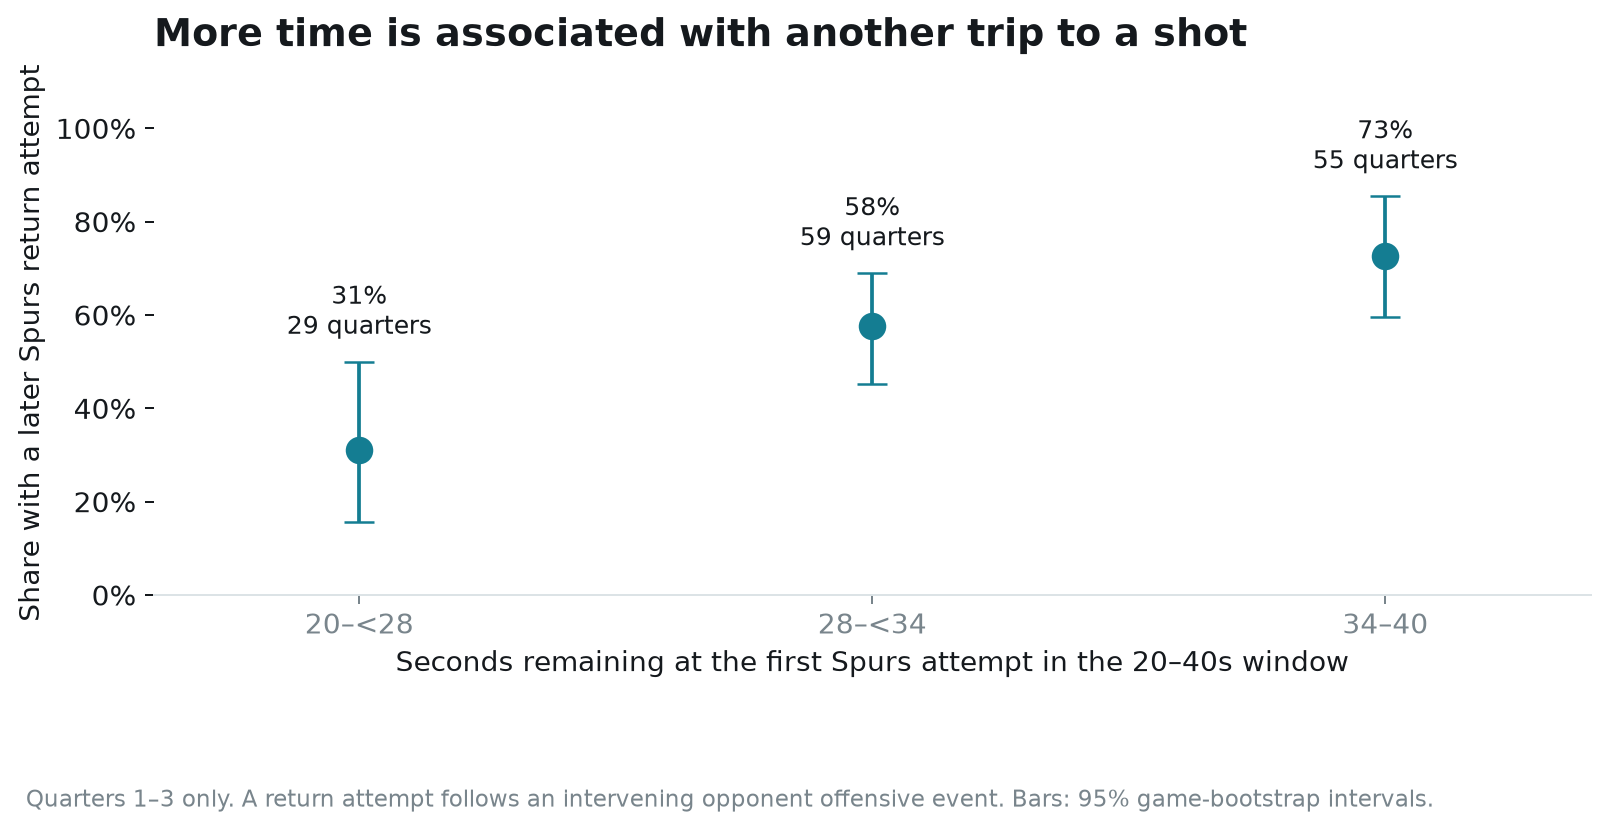

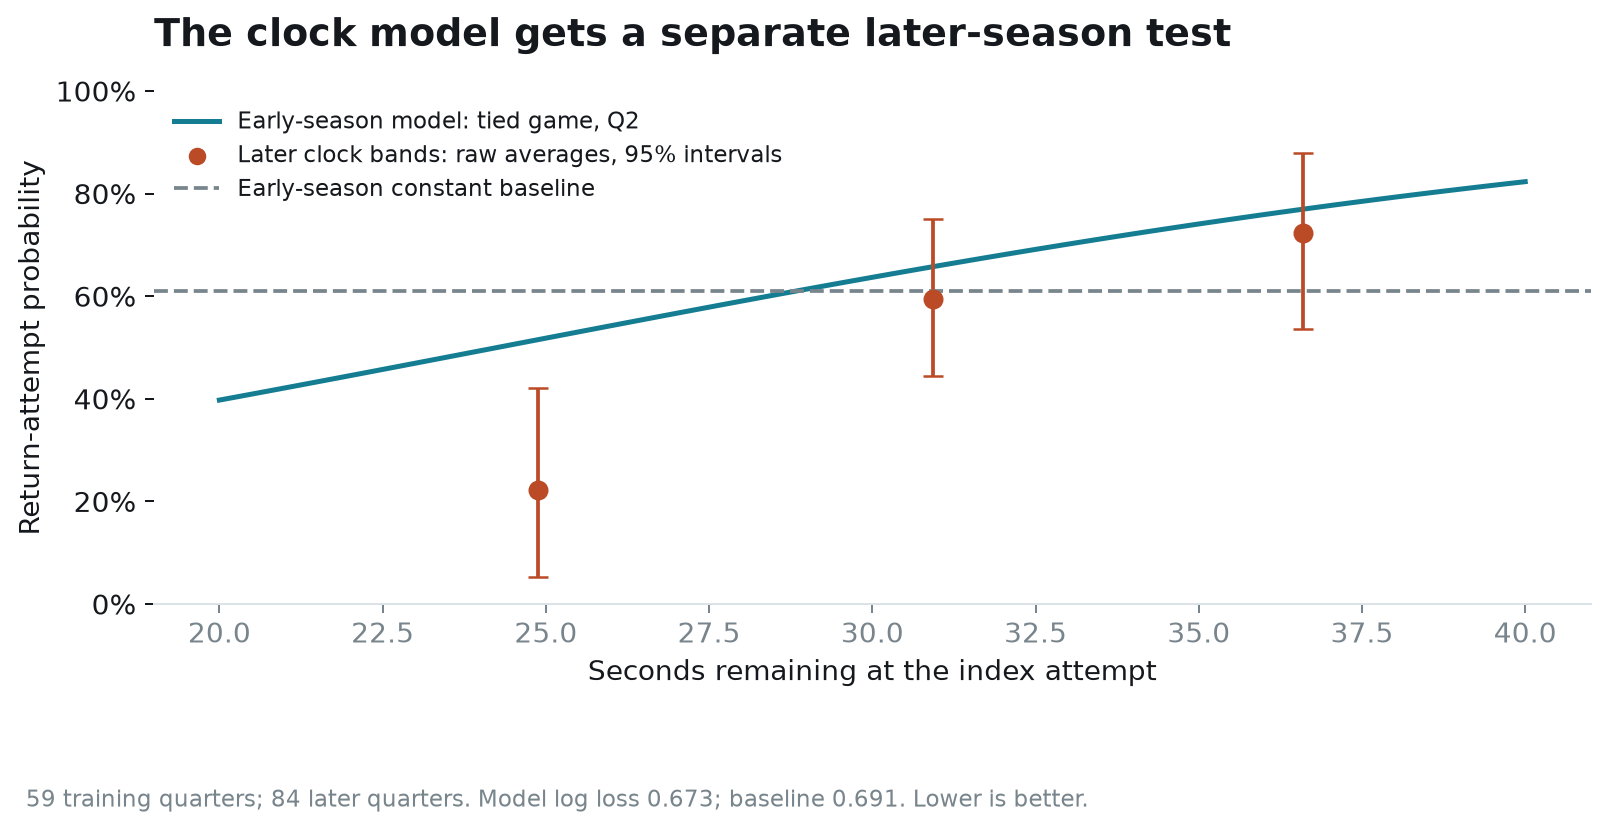

In [3]:
display(Image(filename='figures/quarter_return.png'))
display(Image(filename='figures/quarter_forecast.png'))

## Reproduce predictions from the saved coefficients
The fit uses only pre-January quarters. The later outcomes are used for evaluation.

In [4]:
import json, numpy as np
from src.quarter_clock import design
held = pd.read_csv('results/quarter_holdout.csv')
model = json.loads(Path('results/quarter_model.json').read_text())
coef = np.array(list(model['coefficients'].values()))
p = 1 / (1 + np.exp(-(design(held) @ coef + model['intercept'])))
assert np.allclose(p, held.prediction)
display(held[['date','seconds','return_attempt','prediction','baseline']].head(12))
display(model)

,date,seconds,return_attempt,prediction,baseline
0,2026-01-02,29.2,1,0.533724,0.610169
1,2026-01-02,39.5,1,0.667043,0.610169
2,2026-01-03,39.8,0,0.714259,0.610169
3,2026-01-03,33.5,0,0.705290,0.610169
4,2026-01-03,24.5,0,0.245598,0.610169
5,2026-01-06,29.7,1,0.615616,0.610169
6,2026-01-06,29.7,0,0.687437,0.610169
7,2026-01-07,24.9,0,0.452750,0.610169
8,2026-01-07,31.5,1,0.502122,0.610169
9,2026-01-11,32.3,0,0.569062,0.610169


{'intercept': 0.2770816209332621,
 'coefficients': {'clock_per_5_seconds': 0.48876202151483694,
  'margin_per_10_points': 0.3188942735012722,
  'period_2': 0.28529090231932114,
  'period_3': -0.7022265069583353},
 'C': 1,
 'training_cutoff': '2026-01-01',
 'features': 'Clock centered at 30 seconds / 5, margin clipped to ±20 / 10, Q2 and Q3 indicators',
 'training_events': 59}

## Interpretation and limits
Read the complete accompanying article for denominators, uncertainty, model selection, and the basketball decisions this analysis cannot identify. The results here are historical research, not a claim of team deployment.